In [ ]:
import os
import yaml
import random
import glob
import cv2
import matplotlib.pyplot as plt

In [2]:
# -----------------------------
# Load YAML
# -----------------------------
with open("data.yaml", "r") as f:
    data = yaml.safe_load(f)

train_dir = data["train"]  # path to images folder
labels_dir = train_dir.replace("images", "labels")

print("Images folder:", train_dir)
print("Labels folder:", labels_dir)

# -----------------------------
# Function to load YOLO Labels
# -----------------------------
def load_yolo_labels(label_path, img_w, img_h):
    boxes = []
    if not os.path.exists(label_path):
        return boxes

    with open(label_path, "r") as f:
        for line in f.readlines():
            cls, x, y, w, h = map(float, line.strip().split())

            # Convert YOLO normalized → pixel coordinates
            x_center = x * img_w
            y_center = y * img_h
            w_px = w * img_w
            h_px = h * img_h

            x1 = int(x_center - w_px / 2)
            y1 = int(y_center - h_px / 2)
            x2 = int(x_center + w_px / 2)
            y2 = int(y_center + h_px / 2)

            boxes.append((int(cls), x1, y1, x2, y2))
    return boxes


Images folder: ./data/train/images
Labels folder: ./data/train/labels


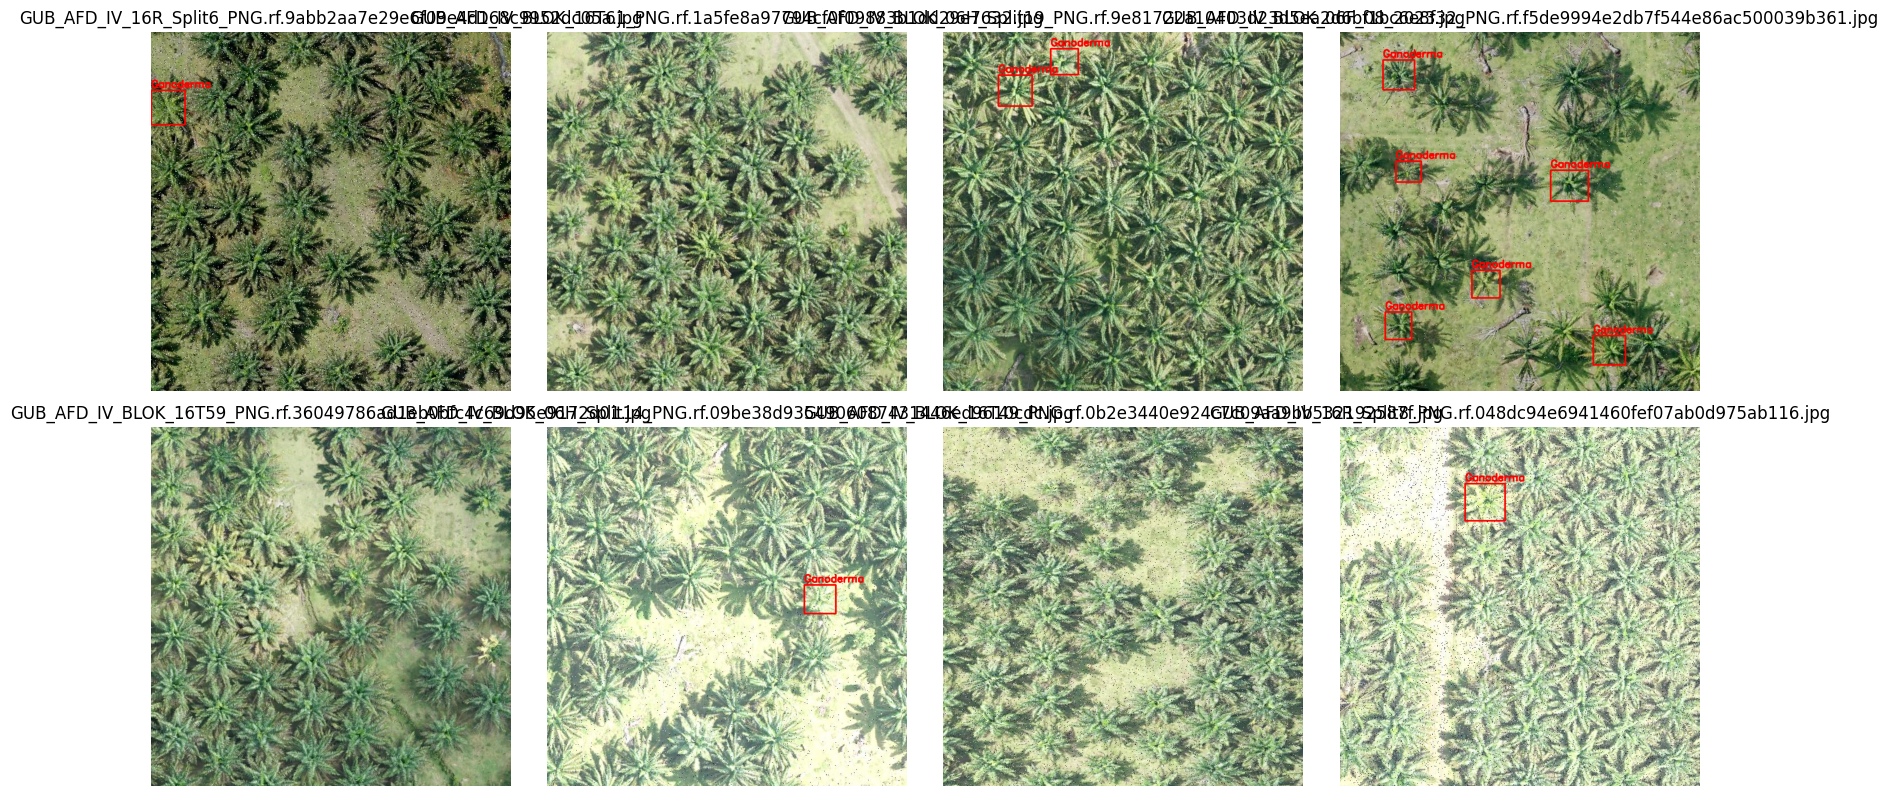

In [ ]:
# -----------------------------
# DISPLAY MULTIPLE IMAGES
# -----------------------------

NUM_IMAGES_TO_SHOW = 8   # <-- Change this number (how many images you want to show)

image_paths = glob.glob(os.path.join(train_dir, "*.jpg")) + \
              glob.glob(os.path.join(train_dir, "*.png")) + \
              glob.glob(os.path.join(train_dir, "*.jpeg"))

random.shuffle(image_paths)
image_paths = image_paths[:NUM_IMAGES_TO_SHOW]

cols = 4
rows = int(len(image_paths) / cols) + 1

plt.figure(figsize=(16, 12))

for idx, img_path in enumerate(image_paths):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]

    # Load matching label file
    label_file = os.path.join(labels_dir, os.path.basename(img_path).replace(".jpg", ".txt").replace(".png", ".txt"))
    boxes = load_yolo_labels(label_file, w, h)

    # Draw bounding boxes
    for cls, x1, y1, x2, y2 in boxes:
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(img, data["names"][cls], (x1, y1 - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

    plt.subplot(rows, cols, idx + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(os.path.basename(img_path))

plt.tight_layout()
plt.show()
